# Clase 08 — Exploración Inicial y Visualización Básica

> Notebook de práctica. Ejecutá las celdas a medida que avanzás en el artículo.

¡Bienvenido al equipo de datos de **TechMarket**!

La empresa acaba de finalizar una migración completa de su sistema de ventas hacia una nueva plataforma. Como ocurre en cualquier proyecto de migración, nadie sabe con certeza si toda la información llegó correctamente. Durante este laboratorio realizarás exactamente el mismo proceso que seguiría un analista de datos en una empresa real al recibir un conjunto de datos por primera vez.

Cada misión representa una solicitud realizada por distintos miembros de la empresa. No se espera que conozcas todas las respuestas de memoria. Utiliza las herramientas aprendidas durante la clase para investigar el dataset y tomar decisiones.


## Escenario

La empresa almacena información de sus productos en una base de datos SQLite. El equipo de ingeniería ya realizó la consulta y cargó los datos en un DataFrame llamado `df`.

In [1]:
import sqlite3
import pandas as pd

conexion = sqlite3.connect("ventas.db")

df = pd.read_sql(
    "SELECT * FROM productos",
    conexion
)

A partir de este momento trabajarás únicamente con el DataFrame.

### Ejercicio 1 — ¿Llegaron todos los datos?

Durante la madrugada se ejecutó una consulta SQL para obtener el catálogo completo de productos que actualmente comercializa la empresa. Antes de comenzar cualquier análisis, tu supervisor quiere asegurarse de que la consulta SQL devolvió una cantidad razonable de información.

**Tu tarea**

Determina:

- ¿Cuántos registros recibió el DataFrame?
- ¿Cuántas columnas contiene?

In [2]:
# shape devuelve (filas, columnas).
filas, columnas = df.shape

print(f"Registros recibidos: {filas}")
print(f"Columnas recibidas: {columnas}")

Registros recibidos: 250
Columnas recibidas: 5


> **Pregunta para reflexionar**

¿Por qué verificar el tamaño del dataset debería ser una de las primeras tareas de cualquier analista de datos?

**Respuesta:** porque permite comprobar rápidamente si la carga parece completa. Si se esperaban 250 productos y llegan muchos menos registros o columnas, conviene detectar el problema antes de calcular, graficar o sacar conclusiones con datos incompletos.

### Ejercicio 2 — Primera inspección visual

Ahora debes comprobar rápidamente que los datos realmente representan productos. Muchas veces una consulta SQL devuelve columnas equivocadas, datos mezclados o incluso tablas incorrectas.

**Consigna:** Realiza una inspección visual del DataFrame y observa:

- nombres de columnas
- primeras filas
- si los datos parecen coherentes


In [3]:
# Revisamos nombres de columnas y una muestra inicial de cinco productos.
print("Columnas:", df.columns.tolist())
display(df.head())

Columnas: ['id', 'nombre', 'categoria', 'precio', 'stock']


,id,nombre,categoria,precio,stock
0,1,Mouse Gamer,gaming,260318.02,31
1,2,Headset,gaming,33167.77,54
2,3,Notebook,tech,197752.04,91
3,4,Auriculares,tech,283872.37,0
4,5,Biblioteca,muebles,56951.39,97


> **Piensa como analista**

¿Detectas algo que te haga desconfiar del dataset?

**Respuesta:** en las primeras cinco filas no se observa una inconsistencia evidente: los IDs comienzan en 1, los productos tienen nombre y categoría, los precios son positivos y el stock es entero. Esta muestra inicial parece coherente, aunque todavía hay que revisar el final y la estructura completa antes de confiar en todo el dataset.

### Ejercicio 3 — Revisando el final de la carga

Durante algunas migraciones los últimos registros pueden quedar incompletos debido a interrupciones durante la exportación.

**Consigna:** Inspecciona las últimas filas del DataFrame. Busca posibles señales de problemas como:

- registros incompletos;
- valores vacíos;
- datos extraños.

In [4]:
# tail() permite inspeccionar los últimos cinco registros de la carga.
display(df.tail())

,id,nombre,categoria,precio,stock
245,246,Monitor,tech,105639.86,100
246,247,Archivador,oficina,16098.38,43
247,248,Teclado Gamer,gaming,59299.78,106
248,249,Soporte Notebook,accesorios,18161.27,46
249,250,Biblioteca,muebles,264079.73,100


### Ejercicio 4 — ¿Qué tipo de información recibimos?

Antes de realizar cálculos necesitas conocer qué representa cada columna. No tendría sentido calcular promedios sobre texto ni contar frecuencias de valores numéricos sin comprender su significado.

**Consigna:** Obtén un resumen de la estructura del DataFrame e identifica:

- nombres de columnas;
- tipos de datos;
- cantidad de valores no nulos.

In [5]:
# info() resume columnas, valores no nulos y tipos de datos.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   id         250 non-null    int64  
 1   nombre     250 non-null    str    
 2   categoria  248 non-null    str    
 3   precio     246 non-null    float64
 4   stock      250 non-null    int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 9.9 KB


> **Pregunta para reflexionar**

¿Por qué resulta peligroso asumir el tipo de una columna sin verificarlo?

**Respuesta:** porque un cálculo puede fallar o producir una conclusión incorrecta si la columna no tiene el tipo esperado. Por ejemplo, un precio guardado como texto no se puede promediar correctamente sin convertirlo; y una categoría no debe tratarse como si fuera una medida numérica. `df.info()` también revela valores faltantes: aquí `categoria` tiene 248 valores no nulos y `precio` 246, sobre 250 filas.

### Ejercicio 5 — Buscando valores sospechosos

El gerente financiero cree que algunos productos podrían haberse cargado con precios incorrectos. No quiere revisar miles de registros manualmente.

**Consigna:** Realiza una exploración estadística de las columnas numéricas e intenta responder:

- ¿Cuál es el precio mínimo?
- ¿Cuál es el máximo?
- ¿El promedio parece razonable?
- ¿Observas algún valor que llame la atención?

In [6]:
# describe() resume las columnas numéricas e ignora los valores faltantes.
estadisticas = df[["precio", "stock"]].describe()
display(estadisticas)

precio_minimo = df["precio"].min()
precio_maximo = df["precio"].max()
precio_promedio = df["precio"].mean()

print(f"Precio mínimo: ${precio_minimo:,.2f}")
print(f"Precio máximo: ${precio_maximo:,.2f}")
print(f"Precio promedio: ${precio_promedio:,.2f}")

# Identificamos el producto con el precio máximo y cualquier stock negativo.
print("\nProducto con el precio más alto:")
display(df.loc[df["precio"].idxmax(), ["id", "nombre", "categoria", "precio", "stock"]].to_frame().T)

print("\nProductos con stock negativo:")
display(df[df["stock"] < 0])

print("\nConclusión: el promedio ($189,242.22) está cerca de la mediana ($184,949.30),")
print("pero el Cable HDMI de $2,500,000 y los stocks negativos requieren revisión.")

,precio,stock
count,2.460000e+02,250.000000
mean,1.892422e+05,59.024000
std,1.792635e+05,35.311571
min,4.230350e+03,-2.000000
25%,9.113853e+04,28.000000
50%,1.849493e+05,60.000000
75%,2.700179e+05,91.750000
max,2.500000e+06,120.000000


Precio mínimo: $4,230.35
Precio máximo: $2,500,000.00
Precio promedio: $189,242.22

Producto con el precio más alto:


,id,nombre,categoria,precio,stock
10,11,Cable HDMI,accesorios,2500000.0,21



Productos con stock negativo:


,id,nombre,categoria,precio,stock
156,157,Resma A4,oficina,185505.03,-2
211,212,Auriculares,tech,322773.52,-2



Conclusión: el promedio ($189,242.22) está cerca de la mediana ($184,949.30),
pero el Cable HDMI de $2,500,000 y el stock negativo requieren revisión.


### Ejercicio 6 — Entendiendo el catálogo

El director comercial quiere conocer cómo está distribuido el catálogo de productos.

**Consigna:** Genera un resumen que responda:

- ¿Cuántos productos existen por categoría?
- ¿Cuál es la categoría más grande?
- ¿Cuál es la menos representada?

In [7]:
# Contamos categorías y mostramos también los valores faltantes.
categorias = df["categoria"].value_counts(dropna=False)
print("Productos por categoría (incluye valores faltantes):")
display(categorias)

# Para comparar categorías comerciales, excluimos los valores faltantes.
categorias_validas = df["categoria"].value_counts()
categoria_mayor = categorias_validas.idxmax()
categoria_menor = categorias_validas.idxmin()

print(f"\nCategoría más grande: {categoria_mayor} ({categorias_validas.max()} productos)")
print(f"Categoría menos representada: {categoria_menor} ({categorias_validas.min()} productos)")
print(f"Registros sin categoría: {df["categoria"].isna().sum()}")

Productos por categoría (incluye valores faltantes):


categoria
tech          90
muebles       57
gaming        40
oficina       35
accesorios    26
NaN            2
Name: count, dtype: int64


Categoría más grande: tech (90 productos)
Categoría menos representada: accesorios (26 productos)
Registros sin categoría: 2


### Ejercicio 7 — ¿Qué porcentaje representa cada categoría?

Las cantidades son útiles, pero la dirección prefiere trabajar con porcentajes.

**Consigna:** Calcula qué porcentaje del catálogo pertenece a cada categoría.

In [8]:
# fillna incluye los 2 registros sin categoría en el total del catálogo.
porcentajes_categoria = (
    df["categoria"].fillna("Sin categoría").value_counts(normalize=True).mul(100).round(2)
)

print("Porcentaje del catálogo por categoría:")
display(porcentajes_categoria)

Porcentaje del catálogo por categoría:


categoria
tech             36.0
muebles          22.8
gaming           16.0
oficina          14.0
accesorios       10.4
Sin categoría     0.8
Name: proportion, dtype: float64

> **Pregunta para reflexionar**

¿Por qué los porcentajes suelen ser más útiles que los valores absolutos cuando se comparan empresas de distintos tamaños?

**Respuesta:** porque expresan la proporción dentro del total y permiten comparar distribuciones aunque las empresas tengan cantidades de productos muy diferentes. Por ejemplo, 90 productos puede ser mucho para una empresa pequeña y poco para una grande; 36 % tiene el mismo significado relativo en ambas.


### Ejercicio 8 — Preparando una reunión ejecutiva

Mañana habrá una reunión con la dirección y nadie quiere leer una tabla con números.

**Consigna:** Construye un gráfico de barras que permita visualizar rápidamente la cantidad de productos por categoría.


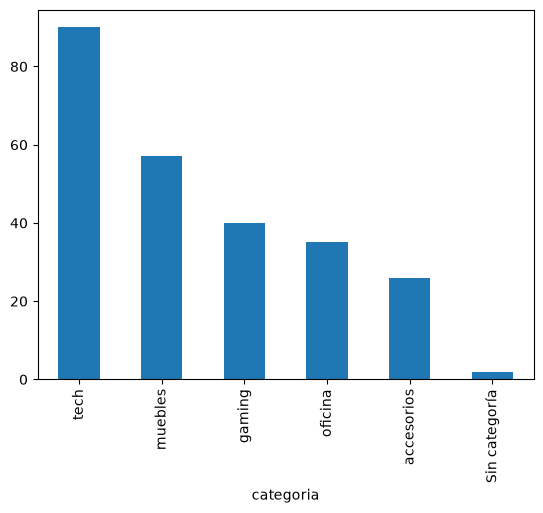

In [9]:
import matplotlib.pyplot as plt

# Un gráfico de barras facilita comparar rápidamente las cantidades.
conteo_categorias = df["categoria"].fillna("Sin categoría").value_counts()
conteo_categorias.plot(kind="bar")
plt.show()

### Ejercicio 9 — Un gráfico listo para presentar


El gráfico anterior será incorporado a un informe ejecutivo. Debe poder entenderse sin necesidad de explicaciones adicionales.

**Consigna:** Mejora el gráfico agregando:

- título;
- nombre del eje X;
- nombre del eje Y.

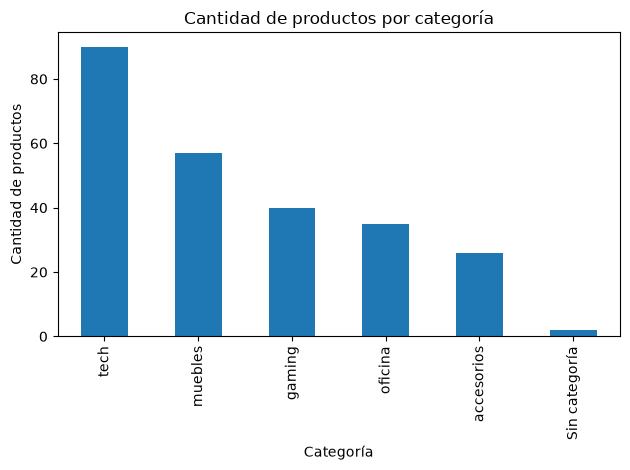

In [10]:
import matplotlib.pyplot as plt

conteo_categorias = df["categoria"].fillna("Sin categoría").value_counts()
conteo_categorias.plot(kind="bar")
plt.title("Cantidad de productos por categoría")
plt.xlabel("Categoría")
plt.ylabel("Cantidad de productos")
plt.tight_layout()
plt.show()

### Ejercicio 10 — Tu primer informe de exploración

Has terminado la revisión inicial del dataset.Antes de entregarlo al resto del equipo debes elaborar un pequeño informe técnico.

**Consigna:** Responde las siguientes preguntas utilizando toda la información obtenida durante las misiones anteriores.

1. ¿Cuántos registros contiene el dataset?

2. ¿Cuántas variables fueron recibidas?

3. ¿Existen columnas con datos faltantes?

4. ¿Qué tipos de datos predominan?

5. ¿Cuál es la categoría con mayor cantidad de productos?

6. ¿Observaste valores que podrían requerir una limpieza posterior?

7. ¿Consideras que el dataset está listo para comenzar un análisis más profundo? Justifica tu respuesta.


In [11]:
filas, columnas = df.shape
faltantes = df.isna().sum()
categoria_principal = df["categoria"].value_counts().idxmax()
cantidad_categoria_principal = df["categoria"].value_counts().max()
stocks_negativos = (df["stock"] < 0).sum()
producto_mas_caro = df.loc[df["precio"].idxmax(), "nombre"]
precio_maximo = df["precio"].max()

informe = f"""INFORME DE EXPLORACIÓN INICIAL — TECHMARKET

1. El dataset contiene {filas} registros.
2. Se recibieron {columnas} variables: id, nombre, categoria, precio y stock.
3. Sí existen datos faltantes: categoria tiene {faltantes['categoria']} y precio tiene {faltantes['precio']} valores nulos.
4. Predominan dos columnas de texto (nombre y categoria) y dos enteras (id y stock); precio es decimal.
5. La categoría con más productos es {categoria_principal}, con {cantidad_categoria_principal} productos.
6. Requieren limpieza o validación: {faltantes['categoria']} categorías faltantes, {faltantes['precio']} precios faltantes,
   {stocks_negativos} stocks negativos y el precio de ${precio_maximo:,.2f} de {producto_mas_caro}, que es atípico.
7. El dataset sirve para una exploración inicial, pero no está listo para un análisis profundo hasta
   tratar los valores faltantes y validar los stocks negativos y el precio atípico.
"""

print(informe)

INFORME DE EXPLORACIÓN INICIAL — TECHMARKET

1. El dataset contiene 250 registros.
2. Se recibieron 5 variables: id, nombre, categoria, precio y stock.
3. Sí existen datos faltantes: categoria tiene 2 y precio tiene 4 valores nulos.
4. Predominan dos columnas de texto (nombre y categoria) y dos enteras (id y stock); precio es decimal.
5. La categoría con más productos es tech, con 90 productos.
6. Requieren limpieza o validación: 2 categorías faltantes, 4 precios faltantes,
   2 stocks negativos y el precio de $2,500,000.00 de Cable HDMI, que es atípico.
7. El dataset sirve para una exploración inicial, pero no está listo para un análisis profundo hasta
   tratar los valores faltantes y validar los stocks negativos y el precio atípico.

